In [36]:
#import all the libraries

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

os.makedirs("outputs", exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("All libraries imported successfully!")

All libraries imported successfully!


In [37]:
#load your uploaded CSV file

df = pd.read_csv("housing.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [38]:
#Knowing the file path of this notebook

import os
print(os.getcwd())
print(os.listdir())

D:\NewProjects\project2
['.ipynb_checkpoints', 'house_price_prediction.ipynb', 'housing.csv', 'outputs']


In [40]:
#Inspect the dataset

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe().round(2))

print("\nMissing values:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nOcean proximity categories:")
display(df["ocean_proximity"].value_counts())

Column names:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB

Statistical summary:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.00,20640.00,20640.00,20640.00,20433.00,20640.00,20640.00,20640.00,20640.00
mean,-119.57,35.63,28.64,2635.76,537.87,1425.48,499.54,3.87,206855.82
std,2.00,2.14,12.59,2181.62,421.39,1132.46,382.33,1.90,115395.62
min,-124.35,32.54,1.00,2.00,1.00,3.00,1.00,0.50,14999.00
25%,-121.80,33.93,18.00,1447.75,296.00,787.00,280.00,2.56,119600.00
50%,-118.49,34.26,29.00,2127.00,435.00,1166.00,409.00,3.53,179700.00
75%,-118.01,37.71,37.00,3148.00,647.00,1725.00,605.00,4.74,264725.00
max,-114.31,41.95,52.00,39320.00,6445.00,35682.00,6082.00,15.00,500001.00



Missing values:


longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


Duplicate rows: 0

Ocean proximity categories:


ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

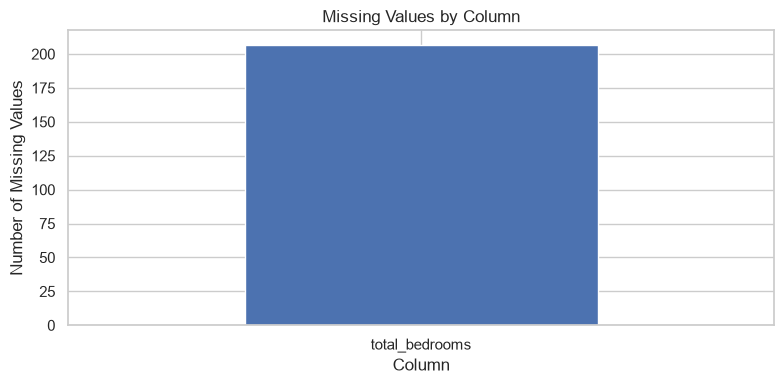

In [41]:
#check the missing values visually

missing = df.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

plt.figure(figsize=(8, 4))

missing.plot(kind="bar")

plt.title("Missing Values by Column")
plt.xlabel("Column")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("outputs/missing_values.png", dpi=180)
plt.show()

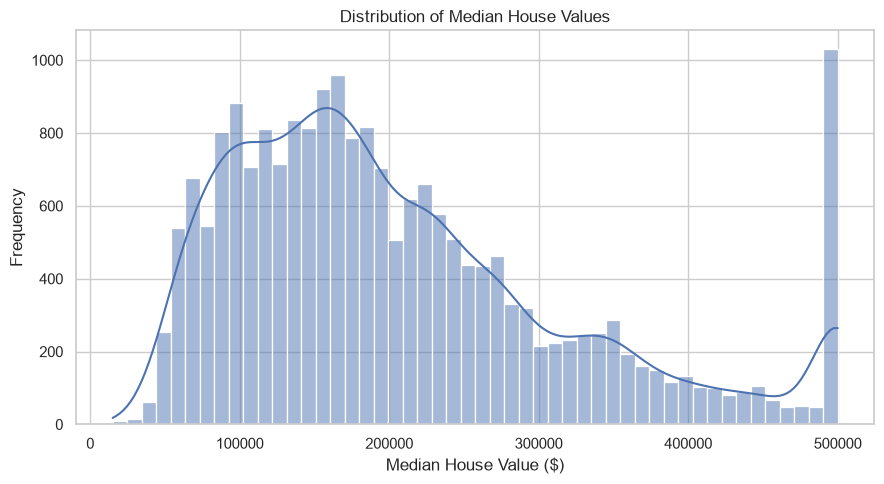

In [42]:
#visualize the target variable 

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="median_house_value",
    bins=50,
    kde=True
)

plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value ($)")
plt.ylabel("Frequency")
plt.tight_layout()

plt.savefig("outputs/house_value_distribution.png", dpi=150)
plt.show()

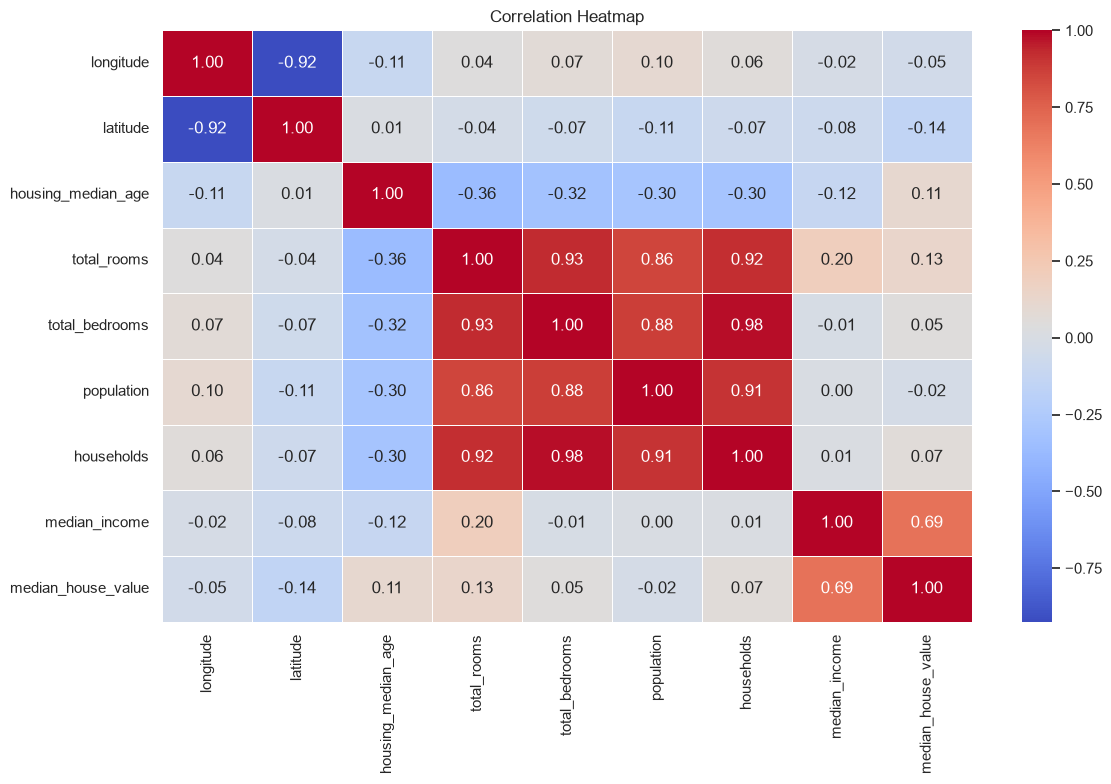

In [43]:
#Analyze numerical correlations

numeric_df = df.select_dtypes(include="number")

correlation_matrix = numeric_df.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()

plt.savefig("outputs/correlation_heatmap.png", dpi=150)
plt.show()

In [44]:
#Display correlations with the target:

target_correlations = (
    correlation_matrix["median_house_value"]
    .drop("median_house_value")
    .sort_values(ascending=False)
)

display(target_correlations.to_frame("Correlation with Target"))

,Correlation with Target
median_income,0.688075
total_rooms,0.134153
housing_median_age,0.105623
households,0.065843
total_bedrooms,0.049686
population,-0.024650
longitude,-0.045967
latitude,-0.144160


In [45]:
"""a positive correlation means two variables tend to increase together; a negative correlation means one tends to decrease as the other increases. Correlation alone does not prove causation.

The heatmap is a first check for multicollinearity. We will use Ridge and Lasso to investigate whether regularization helps with correlated features."""


'a positive correlation means two variables tend to increase together; a negative correlation means one tends to decrease as the other increases. Correlation alone does not prove causation.\n\nThe heatmap is a first check for multicollinearity. We will use Ridge and Lasso to investigate whether regularization helps with correlated features.'

In [46]:
#Create useful additional features

def engineer_features(data):
    data = data.copy()

    data["rooms_per_household"] = (
        data["total_rooms"] /
        data["households"].replace(0, np.nan)
    )

    data["bedrooms_per_room"] = (
        data["total_bedrooms"] /
        data["total_rooms"].replace(0, np.nan)
    )

    data["population_per_household"] = (
        data["population"] /
        data["households"].replace(0, np.nan)
    )

    # Replace infinite values with missing values
    data = data.replace([np.inf, -np.inf], np.nan)

    return data


df_features = engineer_features(df)

print("Original dataset shape:", df.shape)
print("Dataset after feature engineering:", df_features.shape)

display(df_features.head())

Original dataset shape: (20640, 10)
Dataset after feature engineering: (20640, 13)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,rooms_per_household,bedrooms_per_room,population_per_household
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,6.984127,0.146591,2.555556
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,6.238137,0.155797,2.109842
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,8.288136,0.129516,2.802260
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,5.817352,0.184458,2.547945
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,6.281853,0.172096,2.181467


In [47]:
#Separate features and target

X = df_features.drop(columns=["median_house_value"])
y = df_features["median_house_value"]

print("Input feature shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())

Input feature shape: (20640, 12)
Target shape: (20640,)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity,rooms_per_household,bedrooms_per_room,population_per_household
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,NEAR BAY,6.984127,0.146591,2.555556
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,NEAR BAY,6.238137,0.155797,2.109842
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,NEAR BAY,8.288136,0.129516,2.802260
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,NEAR BAY,5.817352,0.184458,2.547945
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,NEAR BAY,6.281853,0.172096,2.181467


0    452600.0
1    358500.0
2    352100.0
3    341300.0
4    342200.0
Name: median_house_value, dtype: float64

In [48]:
#Split into training and testing data

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (16512, 12)
Testing data: (4128, 12)


In [49]:
#Build the preprocessing pipeline

"""Your data requires different processing for different column types.
- Numerical columns: replace missing values using the median, then standardize.
- Categorical columns: replace missing values using the most frequent category, then use one-hot encoding.
- All columns: preprocessing will be fitted only on the training folds during cross-validation."""

numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household']
Categorical features: ['ocean_proximity']


C:\Users\admin\AppData\Local\Temp\ipykernel_10404\1735986793.py:12: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [50]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [51]:
#Build and train the OLS model

ols_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

ols_model.fit(X_train, y_train)

print("OLS model trained successfully!")

OLS model trained successfully!


In [52]:
#Train the baseline Ridge and Lasso models

ridge_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", Ridge(alpha=1.0))
])

lasso_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", Lasso(alpha=1000.0, max_iter=30000))
])

ridge_model.fit(X_train, y_train)
lasso_model.fit(X_train, y_train)

print("Ridge and Lasso baseline models trained successfully!")

Ridge and Lasso baseline models trained successfully!


In [54]:
#Create a model evaluation function

def evaluate_model(model, X_test, y_test):
    predictions = model.predict(X_test)

    rmse = np.sqrt(
        mean_squared_error(y_test, predictions)
    )

    mae = mean_absolute_error(
        y_test, predictions
    )

    r2 = r2_score(
        y_test, predictions
    )

    return {
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    }

In [55]:
#evaluate the baseline models:

baseline_models = {
    "OLS": ols_model,
    "Ridge": ridge_model,
    "Lasso": lasso_model
}

baseline_results = []

for name, model in baseline_models.items():
    scores = evaluate_model(model, X_test, y_test)

    baseline_results.append({
        "Model": name,
        **scores
    })

baseline_results_df = pd.DataFrame(baseline_results)

display(
    baseline_results_df.sort_values(
        "RMSE"
    ).round(2)
)


"""
Lower RMSE is better.
Lower MAE is better.
Higher R² is better."""


,Model,RMSE,MAE,R2
0,OLS,69127.04,49645.49,0.64
1,Ridge,69134.97,49652.14,0.64
2,Lasso,69596.00,49849.54,0.63


'\nLower RMSE is better.\nLower MAE is better.\nHigher R² is better.'

In [56]:
#Tune Ridge Regression

ridge_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", Ridge())
])

ridge_param_grid = {
    "model__alpha": [0.1, 1, 10, 100, 1000, 10000]
}

ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_param_grid,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
    return_train_score=True
)

ridge_search.fit(X_train, y_train)

print("Best Ridge parameters:")
print(ridge_search.best_params_)

print(
    "Best Ridge CV RMSE:",
    round(-ridge_search.best_score_, 2)
)

Best Ridge parameters:
{'model__alpha': 1}
Best Ridge CV RMSE: 67847.59


In [57]:
ridge_cv_results = pd.DataFrame(
    ridge_search.cv_results_
)

display(
    ridge_cv_results[
        [
            "param_model__alpha",
            "mean_test_score",
            "std_test_score"
        ]
    ].sort_values(
        "mean_test_score",
        ascending=False
    ).round(2)
)

,param_model__alpha,mean_test_score,std_test_score
1,1.0,-67847.59,1564.23
0,0.1,-67848.52,1563.06
2,10.0,-67855.05,1554.44
3,100.0,-67891.55,1412.26
4,1000.0,-69053.03,1007.32
5,10000.0,-82578.17,1102.08


In [58]:
#Tune Lasso Regression

lasso_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", Lasso(max_iter=50000, tol=0.001))
])

lasso_param_grid = {
    "model__alpha": [10, 100, 500, 1000, 2000, 5000]
}

lasso_search = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid=lasso_param_grid,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
    return_train_score=True
)

lasso_search.fit(X_train, y_train)

print("Best Lasso parameters:")
print(lasso_search.best_params_)

print(
    "Best Lasso CV RMSE:",
    round(-lasso_search.best_score_, 2)
)

Best Lasso parameters:
{'model__alpha': 10}
Best Lasso CV RMSE: 67850.8


In [59]:
lasso_cv_results = pd.DataFrame(
    lasso_search.cv_results_
)

display(
    lasso_cv_results[
        [
            "param_model__alpha",
            "mean_test_score",
            "std_test_score"
        ]
    ].sort_values(
        "mean_test_score",
        ascending=False
    ).round(2)
)

,param_model__alpha,mean_test_score,std_test_score
0,10,-67850.80,1561.42
1,100,-67860.85,1517.64
2,500,-67950.03,1293.82
3,1000,-68308.46,1055.86
4,2000,-69597.36,759.84
5,5000,-73180.14,765.30


In [60]:
#Evaluate OLS, tuned Ridge and tuned Lasso

final_models = {
    "OLS": ols_model,
    "Ridge (Tuned)": ridge_search.best_estimator_,
    "Lasso (Tuned)": lasso_search.best_estimator_
}

final_results = []
final_predictions = {}

for name, model in final_models.items():

    predictions = model.predict(X_test)

    final_predictions[name] = predictions

    final_results.append({
        "Model": name,
        "RMSE": np.sqrt(
            mean_squared_error(y_test, predictions)
        ),
        "MAE": mean_absolute_error(
            y_test, predictions
        ),
        "R2": r2_score(
            y_test, predictions
        )
    })

final_results_df = pd.DataFrame(final_results)

final_results_df = final_results_df.sort_values(
    "RMSE"
).reset_index(drop=True)

display(final_results_df.round(2))

best_model_name = final_results_df.loc[0, "Model"]

print("Best model based on test RMSE:", best_model_name)

,Model,RMSE,MAE,R2
0,OLS,69127.04,49645.49,0.64
1,Ridge (Tuned),69134.97,49652.14,0.64
2,Lasso (Tuned),69140.32,49654.95,0.64


Best model based on test RMSE: OLS


In [71]:
import os
os.path.abspath("README.md")


'D:\\NewProjects\\project2\\README.md'

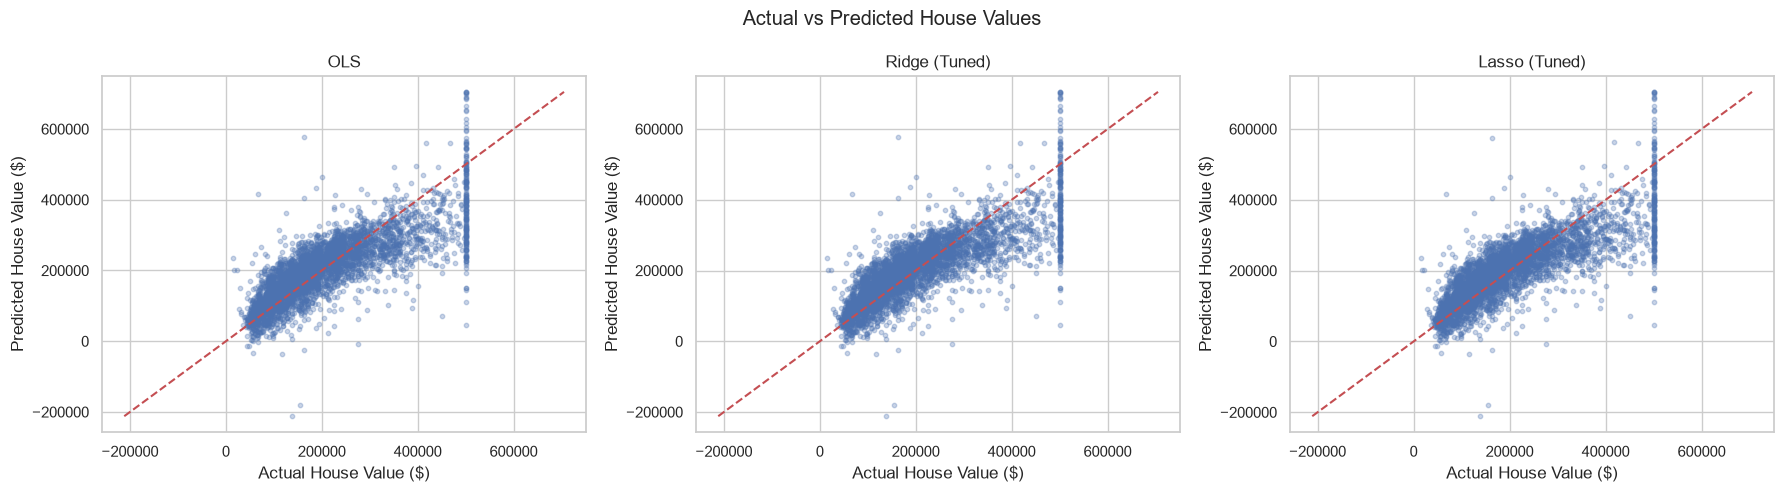

In [61]:
#Actual vs. predicted values

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, predictions) in zip(
    axes, final_predictions.items()
):
    ax.scatter(
        y_test,
        predictions,
        alpha=0.3,
        s=10
    )

    low = min(y_test.min(), predictions.min())
    high = max(y_test.max(), predictions.max())

    ax.plot(
        [low, high],
        [low, high],
        "r--"
    )

    ax.set_title(name)
    ax.set_xlabel("Actual House Value ($)")
    ax.set_ylabel("Predicted House Value ($)")

fig.suptitle("Actual vs Predicted House Values")
plt.tight_layout()

plt.savefig("outputs/actual_vs_predicted.png", dpi=150)
plt.show()

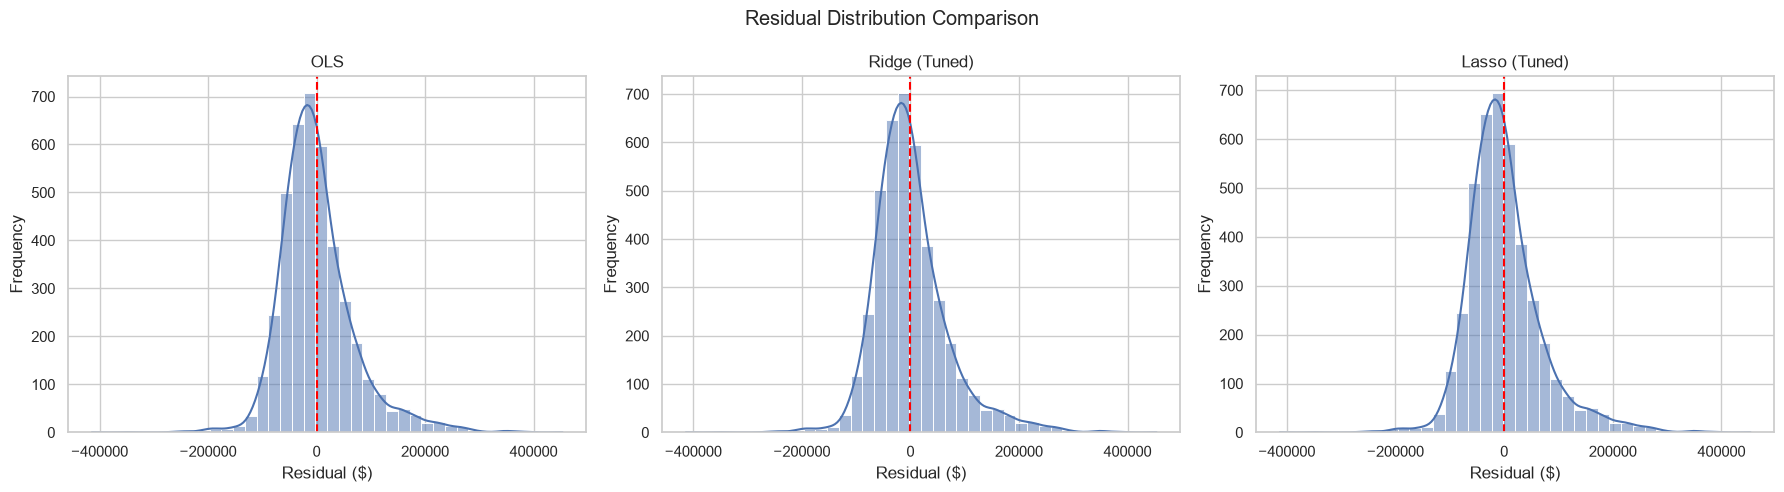

In [62]:
#Plot residual distributions

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, predictions) in zip(
    axes, final_predictions.items()
):
    residuals = y_test.to_numpy() - predictions

    sns.histplot(
        residuals,
        bins=40,
        kde=True,
        ax=ax
    )

    ax.axvline(0, color="red", linestyle="--")
    ax.set_title(name)
    ax.set_xlabel("Residual ($)")
    ax.set_ylabel("Frequency")

fig.suptitle("Residual Distribution Comparison")
plt.tight_layout()

plt.savefig("outputs/residual_distributions.png", dpi=150)
plt.show()

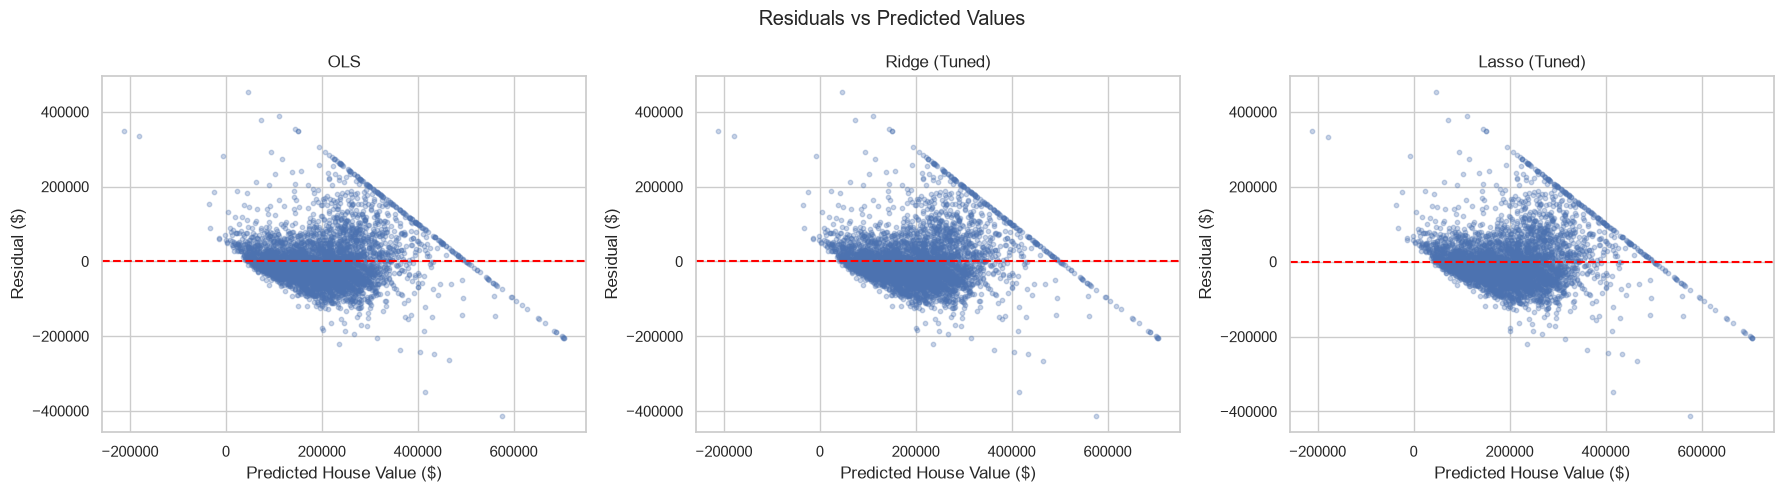

In [63]:
#Plot residuals against predicted values

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, predictions) in zip(
    axes, final_predictions.items()
):
    residuals = y_test.to_numpy() - predictions

    ax.scatter(
        predictions,
        residuals,
        alpha=0.3,
        s=10
    )

    ax.axhline(0, color="red", linestyle="--")
    ax.set_title(name)
    ax.set_xlabel("Predicted House Value ($)")
    ax.set_ylabel("Residual ($)")

fig.suptitle("Residuals vs Predicted Values")
plt.tight_layout()

plt.savefig("outputs/residuals_vs_predicted.png", dpi=150)
plt.show()

In [65]:
#Compare the coefficients of Ridge and Lasso

coefficient_data = {}

for name, model in final_models.items():

    fitted_regressor = model.named_steps["model"]

    feature_names = (
        model.named_steps["preprocessor"]
        .get_feature_names_out()
    )

    coefficient_data[name] = pd.Series(
        fitted_regressor.coef_,
        index=feature_names
    )

coefficient_df = pd.DataFrame(coefficient_data)

display(coefficient_df.round(2))

,OLS,Ridge (Tuned),Lasso (Tuned)
num__longitude,-56276.06,-56221.53,-56098.99
num__latitude,-56638.23,-56586.93,-56484.58
num__housing_median_age,14122.30,14127.71,14113.76
num__total_rooms,5881.10,5878.56,5795.23
num__total_bedrooms,5307.66,5435.69,5511.79
num__population,-46320.29,-46284.33,-46181.03
num__households,40233.72,40073.69,39968.06
num__median_income,78904.44,78903.86,78909.23
num__rooms_per_household,7699.45,7686.16,7665.82
num__bedrooms_per_room,16809.10,16804.40,16777.70


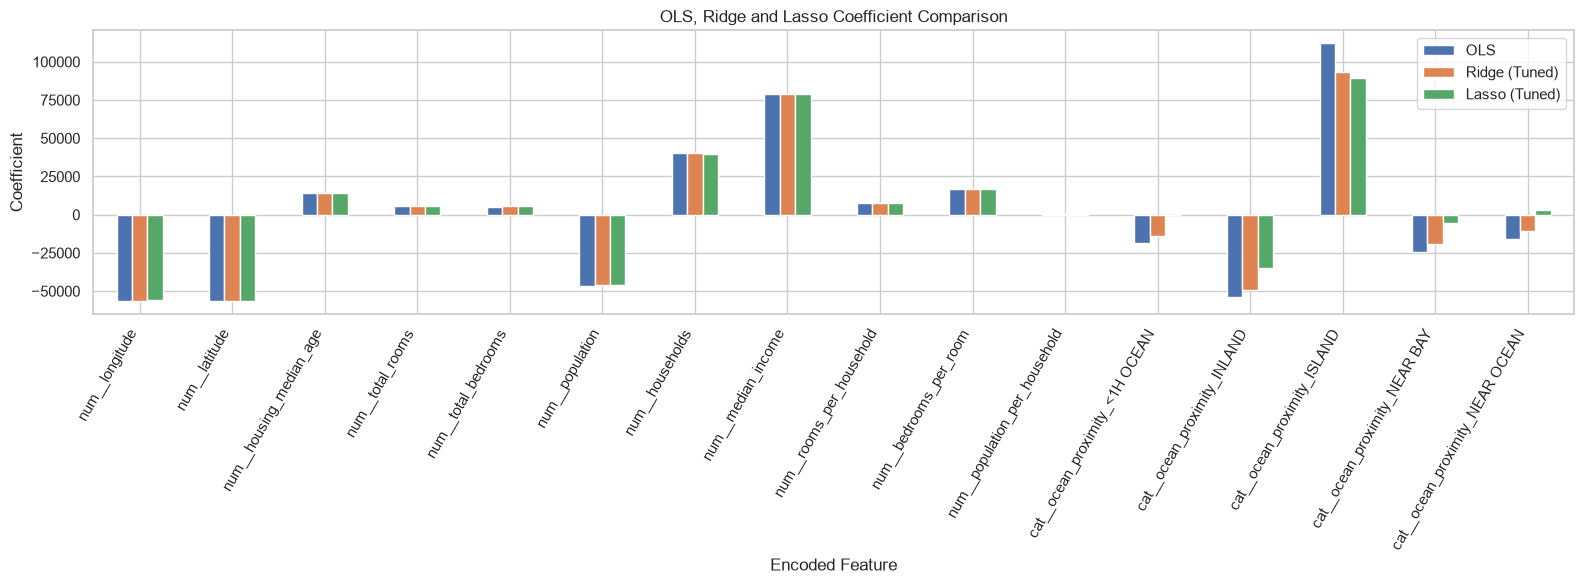

In [66]:
#Plot the coefficients:

coefficient_df.plot(
    kind="bar",
    figsize=(16, 6)
)

plt.title("OLS, Ridge and Lasso Coefficient Comparison")
plt.xlabel("Encoded Feature")
plt.ylabel("Coefficient")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()

plt.savefig("outputs/coefficient_comparison.png", dpi=150)
plt.show()

In [67]:
#Save the model and results

best_model = final_models[best_model_name]

joblib.dump(
    best_model,
    "best_house_price_model.pkl"
)

final_results_df.to_csv(
    "outputs/model_comparison.csv",
    index=False
)

print("Best model:", best_model_name)
print("Model saved successfully!")
print("Results saved successfully!")

Best model: OLS
Model saved successfully!
Results saved successfully!


In [68]:
#Make a prediction for a sample property area

sample_data = pd.DataFrame([{
    "longitude": -122.23,
    "latitude": 37.88,
    "housing_median_age": 30.0,
    "total_rooms": 2000.0,
    "total_bedrooms": 400.0,
    "population": 1000.0,
    "households": 350.0,
    "median_income": 4.5,
    "ocean_proximity": "NEAR BAY"
}])

sample_features = engineer_features(sample_data)

loaded_model = joblib.load(
    "best_house_price_model.pkl"
)

predicted_price = loaded_model.predict(
    sample_features
)[0]

print(f"Predicted median house value: ${predicted_price:,.2f}")

Predicted median house value: $250,432.67
